In [1]:
import pandas as pd

df = pd.read_csv("../data/raw/heart_disease_data.csv")

print(df.head())

   age  sex  cp  trestbps  chol  fbs  restecg  thalach  exang  oldpeak  slope  \
0   63    1   1       145   233    1        2      150      0      2.3      3   
1   67    1   4       160   286    0        2      108      1      1.5      2   
2   67    1   4       120   229    0        2      129      1      2.6      2   
3   37    1   3       130   250    0        0      187      0      3.5      3   
4   41    0   2       130   204    0        2      172      0      1.4      1   

    ca  thal  num  
0  0.0   6.0    0  
1  3.0   3.0    2  
2  2.0   7.0    1  
3  0.0   3.0    0  
4  0.0   3.0    0  


In [2]:
df.shape

(303, 14)

In [3]:
df.columns.to_list()

['age',
 'sex',
 'cp',
 'trestbps',
 'chol',
 'fbs',
 'restecg',
 'thalach',
 'exang',
 'oldpeak',
 'slope',
 'ca',
 'thal',
 'num']

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  num       303 non-null    int64  
dtypes: float64(3), int64(11)
memory usage: 33.3 KB


In [5]:
df.describe()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
count,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,299.000000,301.000000,303.000000
mean,54.438944,0.679868,3.158416,131.689769,246.693069,0.148515,0.990099,149.607261,0.326733,1.039604,1.600660,0.672241,4.734219,0.937294
std,9.038662,0.467299,0.960126,17.599748,51.776918,0.356198,0.994971,22.875003,0.469794,1.161075,0.616226,0.937438,1.939706,1.228536
min,29.000000,0.000000,1.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000
25%,48.000000,0.000000,3.000000,120.000000,211.000000,0.000000,0.000000,133.500000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000
50%,56.000000,1.000000,3.000000,130.000000,241.000000,0.000000,1.000000,153.000000,0.000000,0.800000,2.000000,0.000000,3.000000,0.000000
75%,61.000000,1.000000,4.000000,140.000000,275.000000,0.000000,2.000000,166.000000,1.000000,1.600000,2.000000,1.000000,7.000000,2.000000
max,77.000000,1.000000,4.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,3.000000,3.000000,7.000000,4.000000


In [6]:
df.isnull().sum()

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
num         0
dtype: int64

In [7]:
# Total missing cells
print("Total missing:", df.isnull().sum().sum())

# Percentage missing per column
print((df.isnull().mean() * 100).round(2))

Total missing: 6
age         0.00
sex         0.00
cp          0.00
trestbps    0.00
chol        0.00
fbs         0.00
restecg     0.00
thalach     0.00
exang       0.00
oldpeak     0.00
slope       0.00
ca          1.32
thal        0.66
num         0.00
dtype: float64


In [8]:
# Select one column
print(df["age"].head())

# Select multiple columns
print(df[["age", "chol", "thalach"]].head())

# Inspect the target values
print(df["num"].value_counts().sort_index())

# Check the target data type
print(df["num"].dtype)

0    63
1    67
2    67
3    37
4    41
Name: age, dtype: int64
   age  chol  thalach
0   63   233      150
1   67   286      108
2   67   229      129
3   37   250      187
4   41   204      172
num
0    164
1     55
2     36
3     35
4     13
Name: count, dtype: int64
int64


In [9]:
df["num"].value_counts().sort_index()

num
0    164
1     55
2     36
3     35
4     13
Name: count, dtype: int64

In [10]:
df["num"].value_counts(normalize=True).sort_index().mul(100).round(2)

num
0    54.13
1    18.15
2    11.88
3    11.55
4     4.29
Name: proportion, dtype: float64

In [11]:
# creating a separate binary target
y_binary = (df["num"] > 0).astype(int)

# display class counts
print(y_binary.value_counts().sort_index())

# displaying percentages of each class
print(y_binary.value_counts(normalize=True).sort_index().mul(100).round(2))

num
0    164
1    139
Name: count, dtype: int64
num
0    54.13
1    45.87
Name: proportion, dtype: float64


### Initial Target Distribution Analysis

The dataset contains 303 patient records distributed across five original target categories (0–4). Category 0 accounts for 164 records (54.13%), while category 4 contains 13 records (4.29%).

For the planned binary classification experiment, the target will be derived by mapping category 0 to the negative class and categories 1–4 to the positive class. This produces 164 negative records (54.13%) and 139 positive records (45.87%).

The binary target is relatively balanced, although model performance will still be evaluated using recall, precision, ROC-AUC, and other appropriate metrics rather than accuracy alone. These findings describe the dataset and should not be interpreted as population-level estimates.

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

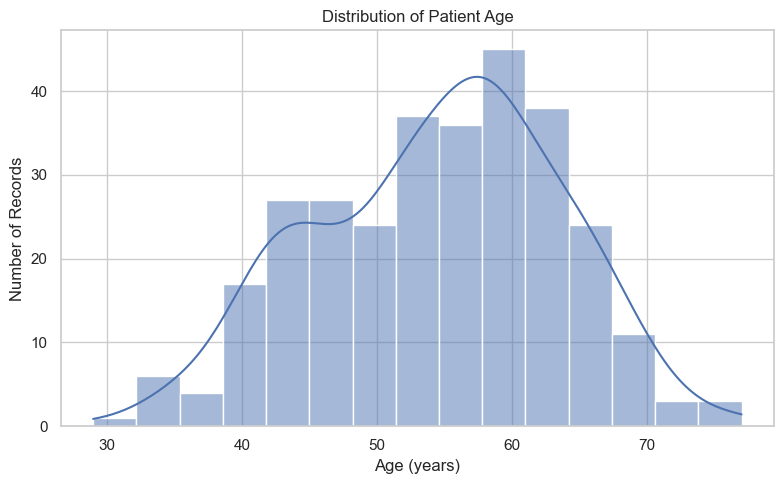

In [13]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="age", bins=15, kde=True)

plt.title("Distribution of Patient Age")
plt.xlabel("Age (years)")
plt.ylabel("Number of Records")

plt.tight_layout()
plt.show()

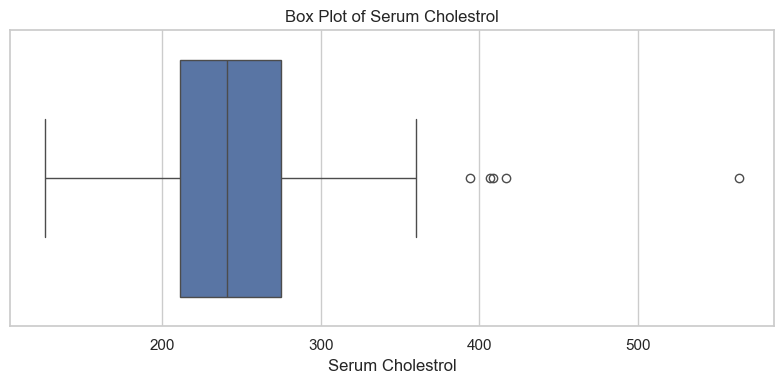

In [14]:
plt.figure(figsize=(8,4))

sns.boxplot(data=df, x="chol")

plt.title("Box Plot of Serum Cholestrol")
plt.xlabel("Serum Cholestrol")

plt.tight_layout()
plt.show()

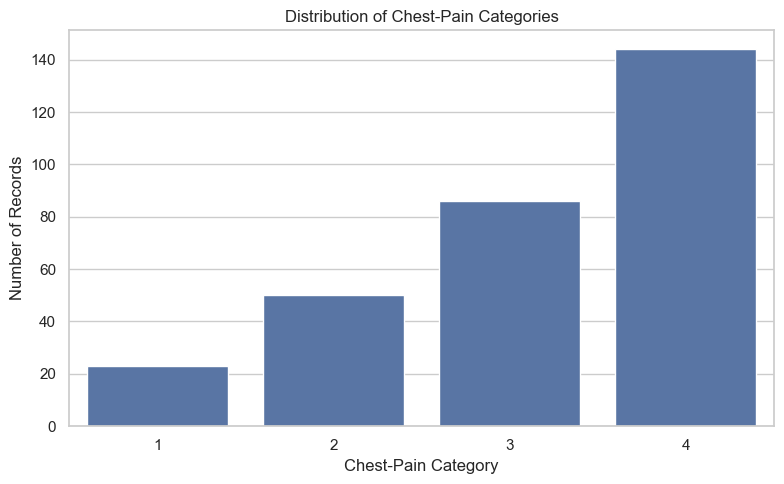

In [15]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="cp")

plt.title("Distribution of Chest-Pain Categories")
plt.xlabel("Chest-Pain Category")
plt.ylabel("Number of Records")

plt.tight_layout()
plt.show()

### Comparing Numerical Features

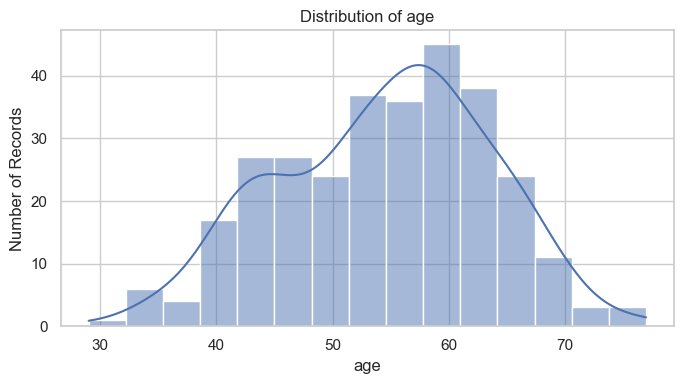

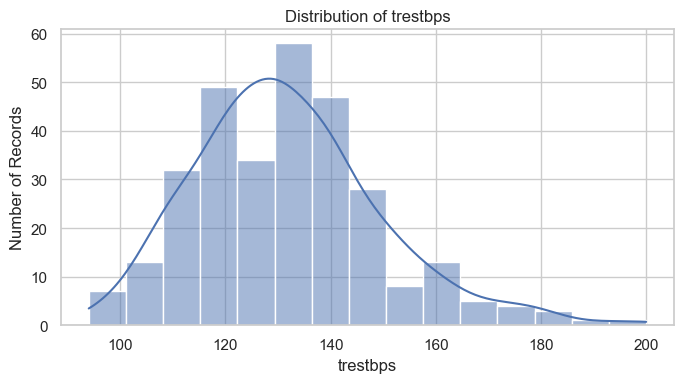

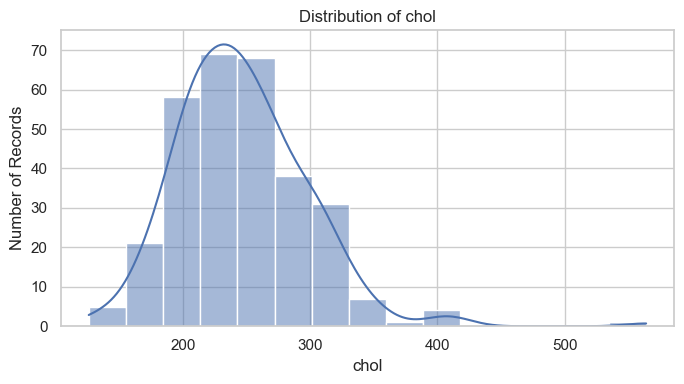

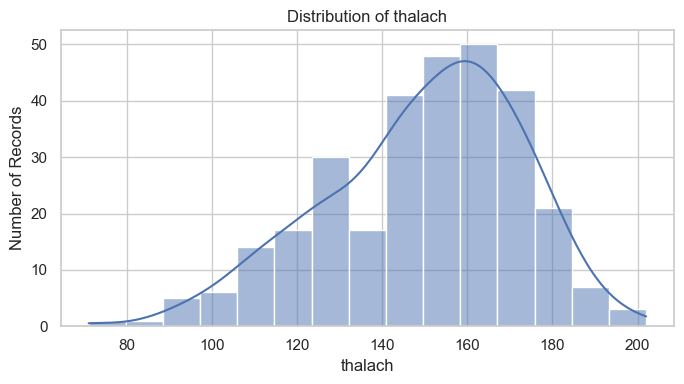

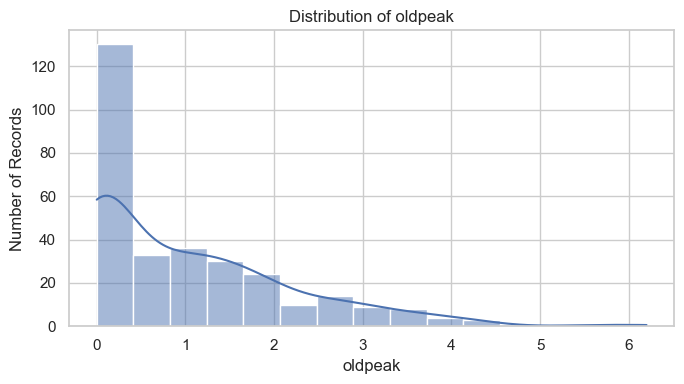

In [18]:
numerical_features = [
    "age",
    "trestbps",
    "chol",
    "thalach",
    "oldpeak"
]

for feature in numerical_features:
    plt.figure(figsize=(7, 4))

    sns.histplot(data=df, x=feature, bins=15, kde=True)

    plt.title(f"Distribution of {feature}")
    plt.xlabel(feature)
    plt.ylabel("Number of Records")

    plt.tight_layout()
    plt.show()

### Comparing features by Target class

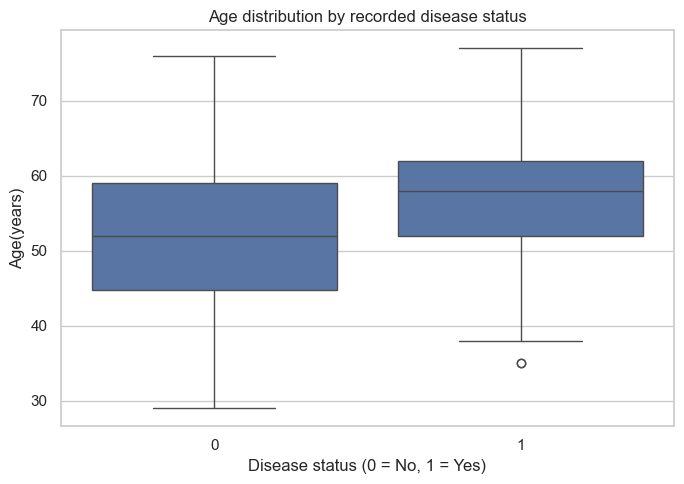

In [19]:
plot_df = df.copy()

plot_df["disease"] = (plot_df["num"] > 0).astype(int)

plt.figure(figsize=(7,5))

sns.boxplot(data=plot_df, x="disease", y="age")

plt.title("Age distribution by recorded disease status")
plt.xlabel("Disease status (0 = No, 1 = Yes)")
plt.ylabel("Age(years)")

plt.tight_layout()
plt.show()